In [ ]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import os
import sys
import time
import json
import joblib
from datetime import datetime
from typing import List, Tuple, Dict, Optional, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import skew, kurtosis, chi2_contingency, mannwhitneyu

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

import shap

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    cross_validate
)
from sklearn.preprocessing import RobustScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import (
    mutual_info_classif, VarianceThreshold, SelectKBest
)
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef,
    log_loss, brier_score_loss,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
    make_scorer
)
from sklearn.calibration import CalibratedClassifierCV

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Matplotlib style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10


PALETTE = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B']
sns.set_palette(PALETTE)

CONFIG = {
    'random_state': RANDOM_STATE,
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'sklearn_version': joblib.__version__,
    'created_at': datetime.now().isoformat(),
    'split_ratios': {'train': 0.70, 'val': 0.15, 'test': 0.15},
    'cv_folds': 5,
    'optuna_trials': 50,
    'mi_k': 50,
    'skew_threshold': 1.0,
    'corr_threshold': 0.95,
    'retention_cost': 50,
    'avg_clv': 1200,
    'retention_success_rate': 0.30
}

print("=" * 60)
print("REPRODUCIBILITY CONFIGURATION")
print("=" * 60)
for k, v in CONFIG.items():
    print(f"{k:20s}: {v}")
print("=" * 60)

REPRODUCIBILITY CONFIGURATION
random_state        : 42
numpy_version       : 1.26.4
pandas_version      : 2.3.3
sklearn_version     : 1.5.3
created_at          : 2026-07-06T20:00:51.220958
split_ratios        : {'train': 0.7, 'val': 0.15, 'test': 0.15}
cv_folds            : 5
optuna_trials       : 50
mi_k                : 50
skew_threshold      : 1.0
corr_threshold      : 0.95
retention_cost      : 50
avg_clv             : 1200
retention_success_rate: 0.3


In [ ]:
CLIENT_PATH = 'telecom/Client.csv'
RECORDS_PATH = 'telecom/Record.csv'

def load_and_merge(client_path: str, records_path: str) -> pd.DataFrame:

    if not os.path.exists(client_path):
        raise FileNotFoundError(f"Client file not found: {client_path}")
    if not os.path.exists(records_path):
        raise FileNotFoundError(f"Records file not found: {records_path}")
    
    client = pd.read_csv(client_path)
    records = pd.read_csv(records_path)
    
    print(f"Client shape:  {client.shape}")
    print(f"Records shape: {records.shape}")
    

    if 'Customer_ID' not in client.columns:
        raise ValueError("Customer_ID missing from client")
    if 'Customer_ID' not in records.columns:
        raise ValueError("Customer_ID missing from records")
    

    df = pd.merge(client, records, on='Customer_ID', how='inner')
    

    assert len(df) == len(client) == len(records), \
        'Lossy merge — investigate join keys. Possible duplicate IDs or missing matches.'
    assert df['Customer_ID'].nunique() == len(df), \
        'Duplicate Customer_IDs after merge'
    assert df.duplicated().sum() == 0, \
        'Duplicate rows detected in merged dataset'
    
    print(f"Merged shape:  {df.shape}")
    return df


df = load_and_merge(CLIENT_PATH, RECORDS_PATH)



TARGET = 'churn'
ID_COL = 'Customer_ID'

# Ensure target is integer
df[TARGET] = df[TARGET].astype(int)

print(f"\n{'='*50}")
print("TARGET DISTRIBUTION")
print(f"{'='*50}")
target_counts = df[TARGET].value_counts().sort_index()
target_props = df[TARGET].value_counts(normalize=True).sort_index()
print(f"Retained (0): {target_counts[0]:,} ({target_props[0]:.3f})")
print(f"Churned  (1): {target_counts[1]:,} ({target_props[1]:.3f})")
print(f"Churn rate:   {df[TARGET].mean():.3f}")
print(f"{'='*50}")

Client shape:  (100000, 50)
Records shape: (100000, 51)
Merged shape:  (100000, 100)

TARGET DISTRIBUTION
Retained (0): 50,438 (0.504)
Churned  (1): 49,562 (0.496)
Churn rate:   0.496


In [ ]:
def inventory_features(df: pd.DataFrame, target: str, id_col: str) -> Dict:
  
    features = [c for c in df.columns if c not in [target, id_col]]
    
    
    num_cols = df[features].select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df[features].select_dtypes(exclude=[np.number]).columns.tolist()
    
    
    cardinality = df[features].nunique().sort_values(ascending=False)
    high_card = cardinality[cardinality > 50].index.tolist()
    low_card = cardinality[cardinality <= 50].index.tolist()
    
    
    missing = df[features].isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_cols = missing_pct[missing_pct > 0].sort_values(ascending=False)
    
    
    mem_mb = df[features].memory_usage(deep=True).sum() / 1024**2
    
    inventory = {
        'total_features': len(features),
        'numeric': num_cols,
        'categorical': cat_cols,
        'high_cardinality': high_card,
        'low_cardinality': low_card,
        'missing': missing_cols.to_dict(),
        'memory_mb': round(mem_mb, 2)
    }
    
    return inventory

inventory = inventory_features(df, TARGET, ID_COL)

print(f"\n{'='*60}")
print("FEATURE INVENTORY")
print(f"{'='*60}")
print(f"Total features:      {inventory['total_features']}")
print(f"Numeric:             {len(inventory['numeric'])}")
print(f"Categorical:         {len(inventory['categorical'])}")
print(f"High cardinality:    {len(inventory['high_cardinality'])}")
print(f"Low cardinality:     {len(inventory['low_cardinality'])}")
print(f"Memory usage:        {inventory['memory_mb']:.2f} MB")
print(f"\nFeatures with missing values: {len(inventory['missing'])}")
if inventory['missing']:
    for col, pct in list(inventory['missing'].items())[:10]:
        print(f"  {col:30s}: {pct:5.2f}%")
print(f"{'='*60}")


FEATURE INVENTORY
Total features:      98
Numeric:             77
Categorical:         21
High cardinality:    65
Low cardinality:     33
Memory usage:        171.88 MB

Features with missing values: 38
  numbcars                      : 49.37%
  dwllsize                      : 38.31%
  HHstatin                      : 37.92%
  ownrent                       : 33.71%
  dwlltype                      : 31.91%
  lor                           : 30.19%
  income                        : 25.44%
  adults                        : 23.02%
  infobase                      : 22.08%
  hnd_webcap                    : 10.19%


In [ ]:
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
if constant_cols:
    print(f"Dropping constant columns: {constant_cols}")
    df = df.drop(columns=constant_cols)
else:
    print("No constant columns found.")

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_cols = missing_pct[missing_pct > 0].sort_values(ascending=False)

print(f"\n{'='*60}")
print("MISSING VALUE ANALYSIS")
print(f"{'='*60}")
print(f"Columns with missing: {len(missing_cols)}")
if len(missing_cols) > 0:
    print(f"{'Column':<30s} {'Missing %':>10s} {'Mechanism':<15s}")
    print("-" * 60)
    for col in missing_cols.index[:15]:
        pct = missing_cols[col]

        if col in ['eqpdays', 'phones', 'models', 'area', 'dualband', 'refurb_new']:
            mech = "MNAR (likely)"
        elif pct < 1.0:
            mech = "MCAR (likely)"
        else:
            mech = "MAR (investigate)"
        print(f"{col:<30s} {pct:>10.2f} {mech:<15s}")
print(f"{'='*60}")

n_duplicates = df.duplicated().sum()
print(f"Exact duplicate rows: {n_duplicates}")
if n_duplicates > 0:
    print("Removing duplicates...")
    df = df.drop_duplicates()


MISSING VALUE ANALYSIS
Columns with missing: 38
Column                          Missing % Mechanism      
------------------------------------------------------------
numbcars                            49.37 MAR (investigate)
dwllsize                            38.31 MAR (investigate)
HHstatin                            37.92 MAR (investigate)
ownrent                             33.71 MAR (investigate)
dwlltype                            31.91 MAR (investigate)
lor                                 30.19 MAR (investigate)
income                              25.44 MAR (investigate)
adults                              23.02 MAR (investigate)
infobase                            22.08 MAR (investigate)
hnd_webcap                          10.19 MAR (investigate)
prizm_social_one                     7.39 MAR (investigate)
avg6mou                              2.84 MAR (investigate)
avg6rev                              2.84 MAR (investigate)
avg6qty                              2.84 MAR (inves

In [ ]:
key_numeric = ['eqpdays', 'hnd_price', 'totmrc_Mean', 'mou_Mean', 'months',
               'custcare_Mean', 'rev_Mean', 'change_mou', 'change_rev']
key_numeric = [c for c in key_numeric if c in df.columns]

print(f"\n{'='*60}")
print("OUTLIER SUMMARY (IQR Method: Q1-1.5*IQR, Q3+1.5*IQR)")
print(f"{'='*60}")
print(f"{'Feature':<20s} {'Outliers':>10s} {'%':>8s} {'Action':<20s}")
print("-" * 60)

for col in key_numeric:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    pct_out = n_out / len(df) * 100
    

    if pct_out > 10:
        action = "Winsorize (extreme)"
    else:
        action = "Retain"
    print(f"{col:<20s} {n_out:>10,} {pct_out:>7.1f}% {action:<20s}")

print(f"{'='*60}")


OUTLIER SUMMARY (IQR Method: Q1-1.5*IQR, Q3+1.5*IQR)
Feature                Outliers        % Action              
------------------------------------------------------------
eqpdays                   2,585     2.6% Retain              
hnd_price                   254     0.3% Retain              
totmrc_Mean               1,800     1.8% Retain              
mou_Mean                  5,154     5.2% Retain              
months                    2,294     2.3% Retain              
custcare_Mean            12,710    12.7% Winsorize (extreme) 
rev_Mean                  5,983     6.0% Retain              
change_mou               13,490    13.5% Winsorize (extreme) 
change_rev               25,816    25.8% Winsorize (extreme) 


In [ ]:
print(f"\n{'='*60}")
print("LOGICAL CONSISTENCY CHECKS")
print(f"{'='*60}")

if 'eqpdays' in df.columns and 'months' in df.columns:
    invalid_eqp = (df['eqpdays'] > df['months'] * 31).sum()
    print(f"Equipment days > months*31: {invalid_eqp} rows")
    if invalid_eqp > 0:
        print("  -> Possible data quality issue: customers with equipment older than tenure")

for col in ['mou_Mean', 'rev_Mean', 'totmrc_Mean']:
    if col in df.columns:
        neg = (df[col] < 0).sum()
        if neg > 0:
            print(f"Negative values in {col}: {neg} rows")
            print(f"  -> Setting negatives to 0 (billing adjustments should be captured separately)")
            df[col] = df[col].clip(lower=0)

if 'hnd_price' in df.columns:
    zero_price = (df['hnd_price'] == 0).sum()
    print(f"Zero handset prices: {zero_price} rows (may indicate BYOD or missing)")

print(f"{'='*60}")


LOGICAL CONSISTENCY CHECKS
Equipment days > months*31: 5145 rows
  -> Possible data quality issue: customers with equipment older than tenure
Negative values in rev_Mean: 5 rows
  -> Setting negatives to 0 (billing adjustments should be captured separately)
Negative values in totmrc_Mean: 23 rows
  -> Setting negatives to 0 (billing adjustments should be captured separately)
Zero handset prices: 0 rows (may indicate BYOD or missing)


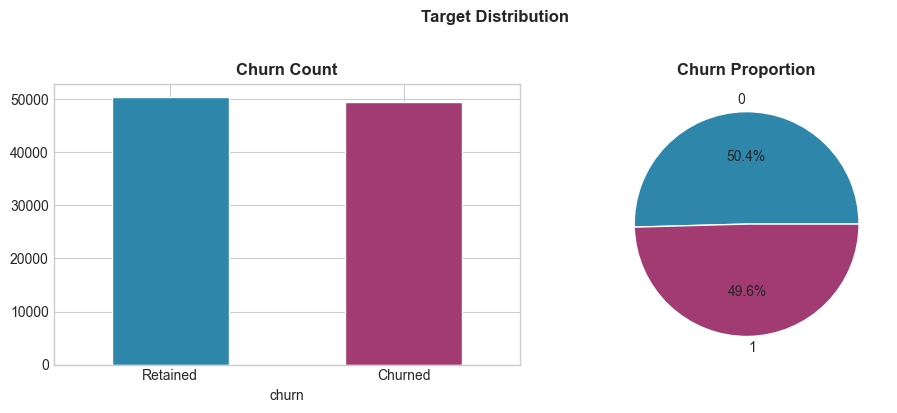


Class balance ratio: 0.496 / 0.504
Imbalance ratio: 1.0:1
No resampling needed — class weights and calibration handle imbalance.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

target_counts.plot(kind='bar', ax=axes[0], color=[PALETTE[0], PALETTE[1]], 
                   edgecolor='white', rot=0)
axes[0].set_title('Churn Count', fontweight='bold')
axes[0].set_xticklabels(['Retained', 'Churned'], rotation=0)

target_props.plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
    colors=[PALETTE[0], PALETTE[1]], wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Churn Proportion', fontweight='bold')
axes[1].set_ylabel('')

plt.suptitle('Target Distribution', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nClass balance ratio: {target_props.min():.3f} / {target_props.max():.3f}")
print(f"Imbalance ratio: {target_counts.max() / target_counts.min():.1f}:1")
print("No resampling needed — class weights and calibration handle imbalance.")

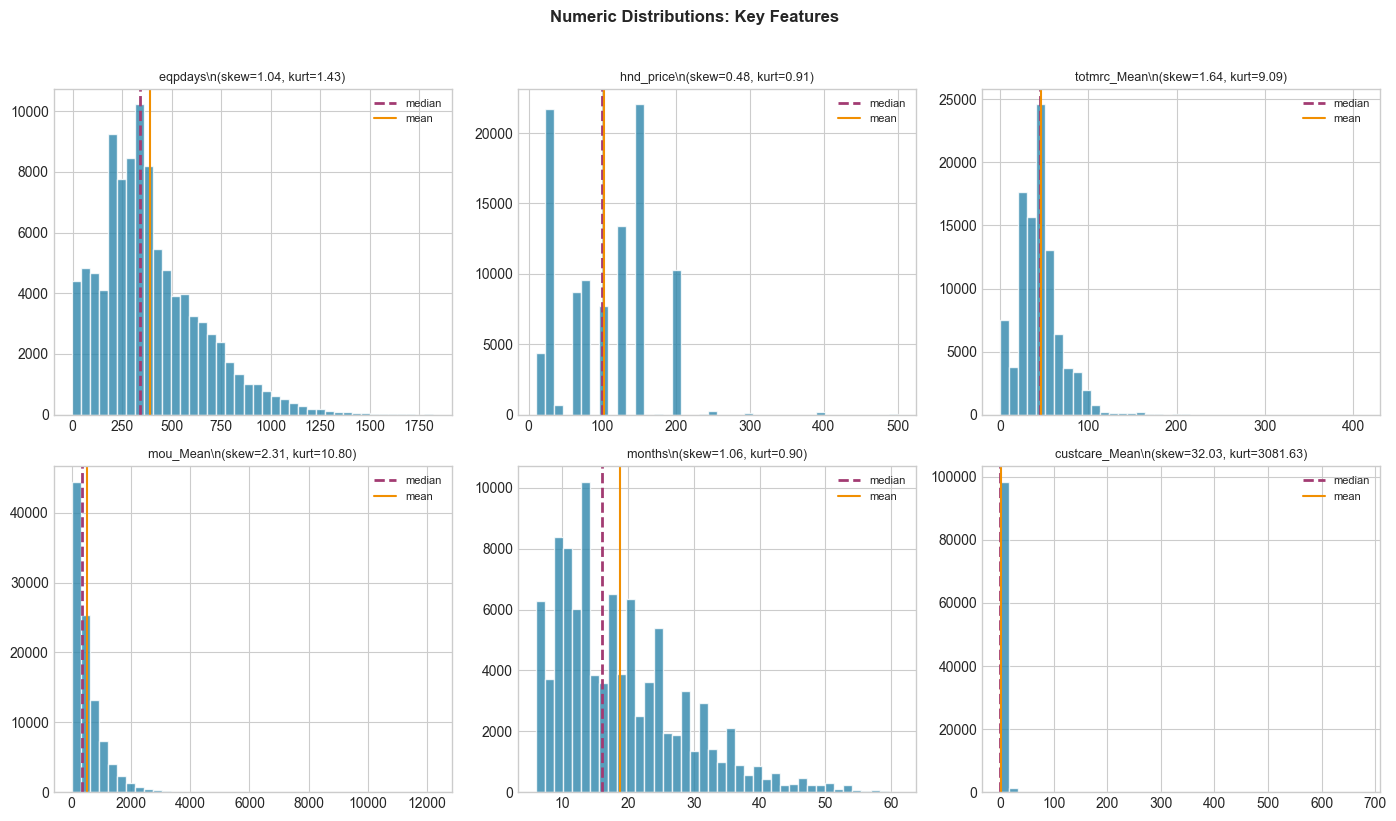

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(key_numeric[:6]):
    data = df[col].dropna()
    data.hist(bins=40, ax=axes[i], color=PALETTE[0], edgecolor='white', alpha=0.8)
    axes[i].axvline(data.median(), color=PALETTE[1], linestyle='--', linewidth=2, label='median')
    axes[i].axvline(data.mean(), color=PALETTE[2], linestyle='-', linewidth=1.5, label='mean')
    
    sk = skew(data)
    ku = kurtosis(data)
    axes[i].set_title(f'{col}\\n(skew={sk:.2f}, kurt={ku:.2f})', fontsize=9)
    axes[i].legend(loc='upper right', fontsize=8)

plt.suptitle('Numeric Distributions: Key Features', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('02_numeric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

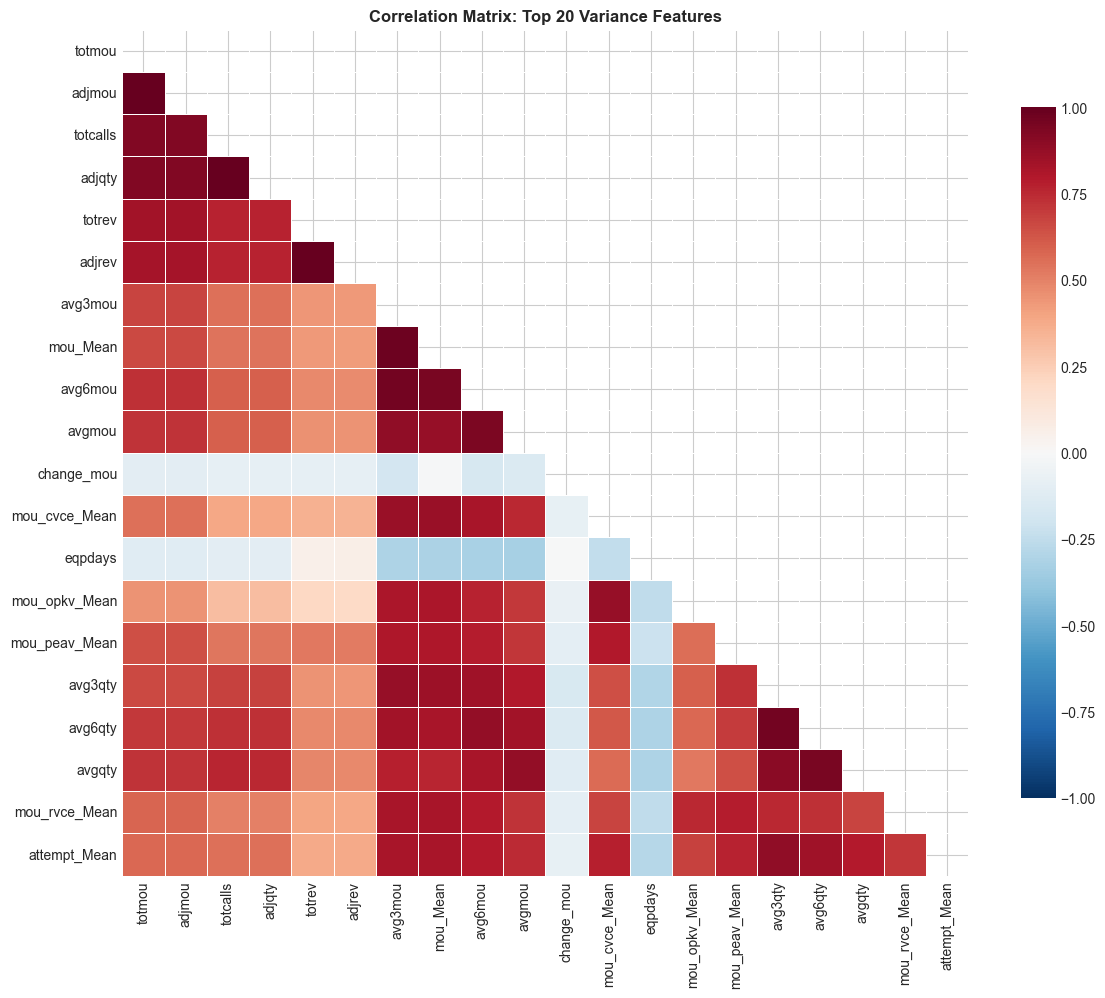

In [25]:
num_all = df.select_dtypes(include=[np.number]).columns.drop([TARGET, ID_COL], errors='ignore').tolist()
top_var = df[num_all].var().sort_values(ascending=False).head(20).index
corr = df[top_var].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, linewidths=0.5,
            vmin=-1, vmax=1, cbar_kws={'shrink': 0.8},
            square=True, annot=False)
plt.title('Correlation Matrix: Top 20 Variance Features', fontweight='bold')
plt.tight_layout()
plt.savefig('03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


BIVARIATE STATISTICAL TESTS (Mann-Whitney U)
Feature              Retained Median  Churned Median      p-value     Effect
----------------------------------------------------------------------
eqpdays                        310.0           366.0     0.00e+00     0.148***
hnd_price                      130.0           100.0    2.35e-229    -0.117***
totmrc_Mean                     45.0            43.4    1.16e-119    -0.085***
mou_Mean                       380.5           329.8    2.28e-103    -0.079***
months                          16.0            17.0     1.62e-43     0.050***
custcare_Mean                    0.0             0.0     5.95e-70    -0.059***


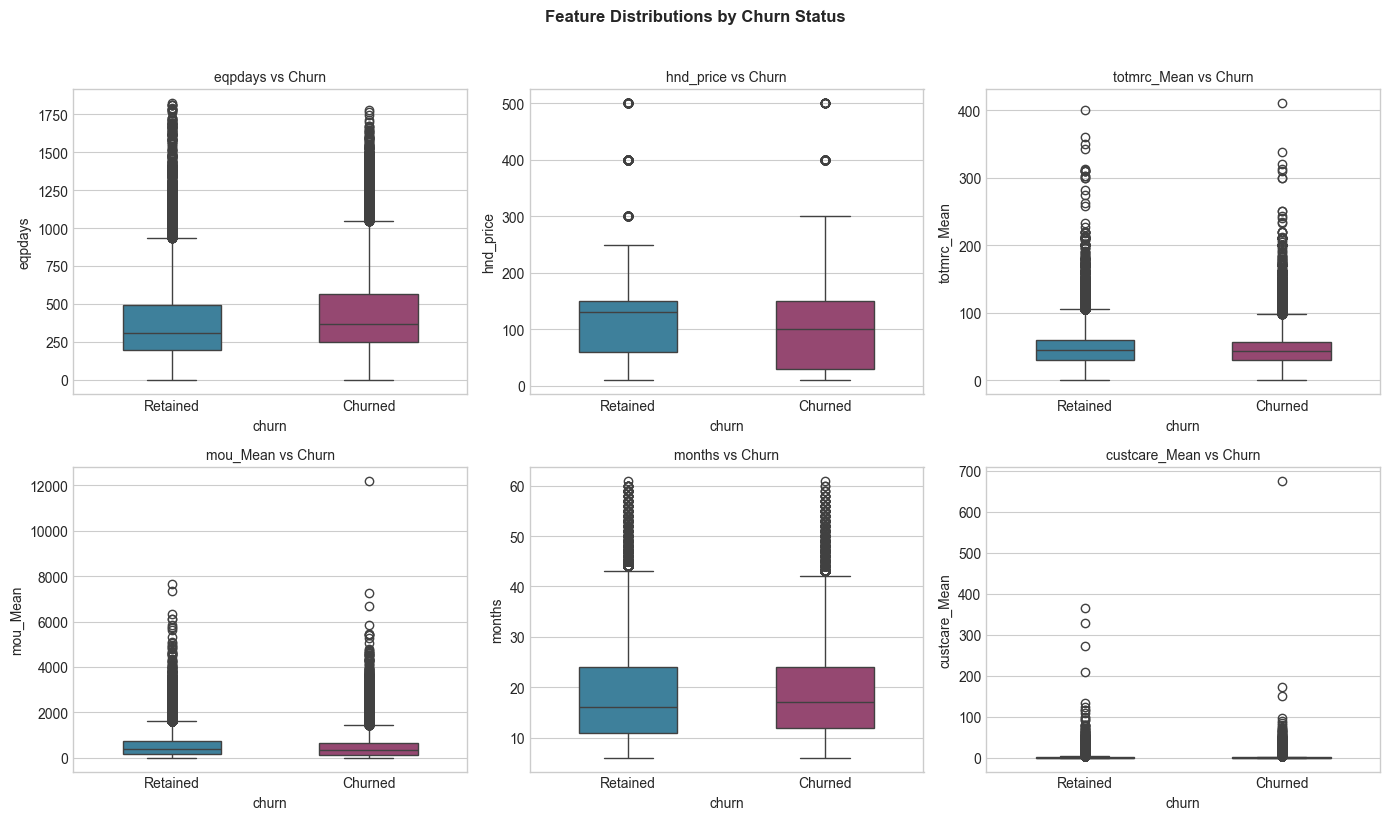

In [ ]:
biv_cols = ['eqpdays', 'hnd_price', 'totmrc_Mean', 'mou_Mean', 'months', 'custcare_Mean']
biv_cols = [c for c in biv_cols if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

print(f"\n{'='*70}")
print("BIVARIATE STATISTICAL TESTS (Mann-Whitney U)")
print(f"{'='*70}")
print(f"{'Feature':<20s} {'Retained Median':>15s} {'Churned Median':>15s} {'p-value':>12s} {'Effect':>10s}")
print("-" * 70)

for i, col in enumerate(biv_cols):
    retained = df[df[TARGET] == 0][col].dropna()
    churned = df[df[TARGET] == 1][col].dropna()

    stat, pval = mannwhitneyu(retained, churned, alternative='two-sided')

    effect = 1 - (2 * stat) / (len(retained) * len(churned))
    
    significance = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "ns"
    
    print(f"{col:<20s} {retained.median():>15.1f} {churned.median():>15.1f} {pval:>12.2e} {effect:>9.3f}{significance}")

    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[i], 
                palette=[PALETTE[0], PALETTE[1]], width=0.5)
    axes[i].set_title(f'{col} vs Churn', fontsize=10)
    axes[i].set_xticklabels(['Retained', 'Churned'])

plt.suptitle('Feature Distributions by Churn Status', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('04_bivariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"{'='*70}")

In [ ]:
print(f"{'='*60}")
print("LEAKAGE AUDIT")
print(f"{'='*60}")

timing_suspect = ['avg6mou', 'avg6qty', 'avg6rev', 'change_mou', 'change_rev']

print("\n6.1.1 Timing Leakage:")
for col in timing_suspect:
    if col in df.columns:
        print(f"  DROP: {col} — may include post-churn period data")

adjustment_suspect = ['adjrev', 'adjmou', 'adjqty']
print("\n6.1.2 Adjustment Leakage:")
for col in adjustment_suspect:
    if col in df.columns:
        print(f"  DROP: {col} — billing adjustments applied after churn known")

proxy_suspect = ['totmou', 'totrev']
print("\n6.1.3 Proxy Leakage:")
for col in proxy_suspect:
    if col in df.columns:
        print(f"  DROP: {col} — aggregate may include churn month partial data")

timing_drop = [c for c in timing_suspect + adjustment_suspect + proxy_suspect if c in df.columns]

LEAKAGE AUDIT

6.1.1 Timing Leakage:
  DROP: avg6mou — may include post-churn period data
  DROP: avg6qty — may include post-churn period data
  DROP: avg6rev — may include post-churn period data
  DROP: change_mou — may include post-churn period data
  DROP: change_rev — may include post-churn period data

6.1.2 Adjustment Leakage:
  DROP: adjrev — billing adjustments applied after churn known
  DROP: adjmou — billing adjustments applied after churn known
  DROP: adjqty — billing adjustments applied after churn known

6.1.3 Proxy Leakage:
  DROP: totmou — aggregate may include churn month partial data
  DROP: totrev — aggregate may include churn month partial data


In [ ]:

redundant_pairs = [
    ('complete_Mean', 'plcd_vce_Mean'),
    ('ccrndmou_Mean', 'mou_Mean'),
    ('plcd_vce_Mean', 'vceovr_Mean'),
    ('plcd_dat_Mean', 'recv_sms_Mean'),
    ('mou_opkd_Mean', 'mou_Mean'),
    ('recv_vce_Mean', 'plcd_vce_Mean'),
    ('totmou', 'mou_Mean'),
    ('totrev', 'rev_Mean'),
    ('ovrrev_Mean', 'ovrmou_Mean'),
    ('callfwdv_Mean', 'custcare_Mean'),
]

redundant_drop = []
print("\n6.2 Redundancy Audit (|r| > 0.95):")
for keep, drop in redundant_pairs:
    if keep in df.columns and drop in df.columns:
        corr_val = df[[keep, drop]].corr().iloc[0, 1]
        if abs(corr_val) > 0.95:
            print(f"  DROP: {drop} (r={corr_val:.3f} with {keep})")
            redundant_drop.append(drop)


6.2 Redundancy Audit (|r| > 0.95):
  DROP: plcd_vce_Mean (r=0.983 with complete_Mean)
  DROP: ovrmou_Mean (r=0.956 with ovrrev_Mean)


In [30]:
drop_cols = list(set(timing_drop + redundant_drop + [ID_COL]))
drop_cols = [c for c in drop_cols if c in df.columns]

print(f"\n{'='*60}")
print(f"LEAKAGE PREVENTION SUMMARY")
print(f"{'='*60}")
print(f"Columns dropped: {len(drop_cols)}")
for c in drop_cols:
    print(f"  - {c}")
print(f"\nRemaining features: {df.shape[1] - 1 - len(drop_cols)}")
print(f"{'='*60}")

# Remove leakage columns
df_clean = df.drop(columns=drop_cols).copy()


LEAKAGE PREVENTION SUMMARY
Columns dropped: 13
  - totrev
  - change_rev
  - avg6rev
  - change_mou
  - Customer_ID
  - totmou
  - adjqty
  - adjmou
  - ovrmou_Mean
  - avg6mou
  - avg6qty
  - adjrev
  - plcd_vce_Mean

Remaining features: 86


In [ ]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=CONFIG['split_ratios']['val'] + CONFIG['split_ratios']['test'],
    random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=CONFIG['split_ratios']['test'] / (CONFIG['split_ratios']['val'] + CONFIG['split_ratios']['test']),
    random_state=RANDOM_STATE, stratify=y_temp
)

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"\n{'='*60}")
print("DATA SPLIT")
print(f"{'='*60}")
print(f"Training:   {len(y_train):,} rows ({len(y_train)/len(y)*100:.1f}%)")
print(f"Validation: {len(y_val):,} rows ({len(y_val)/len(y)*100:.1f}%)")
print(f"Test:       {len(y_test):,} rows ({len(y_test)/len(y)*100:.1f}%)")
print(f"\nChurn rate — Train: {y_train.mean():.3f} | Val: {y_val.mean():.3f} | Test: {y_test.mean():.3f}")
print(f"{'='*60}")



DATA SPLIT
Training:   70,000 rows (70.0%)
Validation: 15,000 rows (15.0%)
Test:       15,000 rows (15.0%)

Churn rate — Train: 0.496 | Val: 0.496 | Test: 0.496


In [ ]:
def engineer_features(dfs: List[pd.DataFrame], fit_df: pd.DataFrame) -> List[pd.DataFrame]:

    result = [df.copy() for df in dfs]
    
    for df in result:

        if 'drop_vce_Mean' in df.columns and 'attempt_Mean' in df.columns:
            df['drop_rate'] = df['drop_vce_Mean'] / (df['attempt_Mean'] + 1)
            df['block_rate'] = df['blck_vce_Mean'] / (df['attempt_Mean'] + 1)
            df['unanswered_rate'] = df['unan_vce_Mean'] / (df['attempt_Mean'] + 1)
            df['service_failure_rate'] = (df['drop_vce_Mean'] + df['blck_vce_Mean']) / (df['attempt_Mean'] + 1)
        

        if 'drop_dat_Mean' in df.columns and 'attempt_Mean' in df.columns:
            df['data_failure_rate'] = (df['drop_dat_Mean'] + df['blck_dat_Mean']) / (df['attempt_Mean'] + 1)
        
        
        if 'ovrmou_Mean' in df.columns and 'mou_Mean' in df.columns:
            df['overage_ratio'] = df['ovrmou_Mean'] / (df['mou_Mean'] + 1)
            df['overage_flag'] = (df['ovrmou_Mean'] > 0).astype(int)
        
        
        if 'roam_Mean' in df.columns and 'mou_Mean' in df.columns:
            df['roam_ratio'] = df['roam_Mean'] / (df['mou_Mean'] + 1)
        
        
        if 'custcare_Mean' in df.columns and 'mou_Mean' in df.columns:
            df['custcare_per_mou'] = df['custcare_Mean'] / (df['mou_Mean'] + 1)
        
        
        if 'rev_Mean' in df.columns and 'avg3rev' in df.columns:
            df['rev_trend'] = df['rev_Mean'] - df['avg3rev']
        if 'mou_Mean' in df.columns and 'avg3mou' in df.columns:
            df['mou_trend'] = df['mou_Mean'] - df['avg3mou']
        
        
        if 'eqpdays' in df.columns and 'months' in df.columns:
            df['equipment_age_ratio'] = df['eqpdays'] / (df['months'] + 1)
        
       
        if 'rev_Mean' in df.columns and 'months' in df.columns:
            df['rev_per_month'] = df['rev_Mean'] / (df['months'] + 1)
        if 'mou_Mean' in df.columns and 'months' in df.columns:
            df['mou_per_month'] = df['mou_Mean'] / (df['months'] + 1)
        
        
        if 'mou_Mean' in df.columns and 'totmrc_Mean' in df.columns:
            df['mou_per_dollar'] = df['mou_Mean'] / (df['totmrc_Mean'] + 1)
        
        
        if 'eqpdays' in df.columns and 'totmrc_Mean' in df.columns:
            df['old_device_low_plan'] = df['eqpdays'] / (df['totmrc_Mean'] + 1)
        if 'months' in df.columns and 'custcare_Mean' in df.columns:
            df['new_dissatisfied'] = df['custcare_Mean'] / (df['months'] + 1)
        
        
        for col in ['area', 'dualband', 'refurb_new', 'eqpdays', 'phones', 'models']:
            if col in df.columns:
                df[f'{col}_missing'] = df[col].isna().astype(int)
    
    return result

original_cols = X_train.columns.tolist()
X_train, X_val, X_test = engineer_features([X_train, X_val, X_test], fit_df=X_train)

eng_cols = [c for c in X_train.columns if c not in original_cols]
print(f"Engineered {len(eng_cols)} new features:")
for c in eng_cols:
    print(f"  - {c}")

Engineered 21 new features:
  - drop_rate
  - block_rate
  - unanswered_rate
  - service_failure_rate
  - data_failure_rate
  - roam_ratio
  - custcare_per_mou
  - rev_trend
  - mou_trend
  - equipment_age_ratio
  - rev_per_month
  - mou_per_month
  - mou_per_dollar
  - old_device_low_plan
  - new_dissatisfied
  - area_missing
  - dualband_missing
  - refurb_new_missing
  - eqpdays_missing
  - phones_missing
  - models_missing


In [34]:
eng_medians = X_train[eng_cols].median()
for d in (X_train, X_val, X_test):
    d[eng_cols] = d[eng_cols].fillna(eng_medians)

print(f"\nTotal features after engineering: {X_train.shape[1]}")


Total features after engineering: 107


In [ ]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
skewed_features = []
shift_map = {}

for c in num_cols:
    sk = skew(X_train[c].dropna())
    if abs(sk) > CONFIG['skew_threshold']:
        skewed_features.append(c)
        m = X_train[c].min()
        shift_map[c] = max(0.0, -m + 1.0) if m < 0 else 0.0

print(f"Log-transforming {len(skewed_features)} skewed features (|skew| > {CONFIG['skew_threshold']})")

for c in skewed_features:
    for d in (X_train, X_val, X_test):
        d[c] = np.log1p(d[c] + shift_map[c])

Log-transforming 79 skewed features (|skew| > 1.0)


In [ ]:
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', RobustScaler())
])

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
], remainder='drop')


X_tr = preprocessor.fit_transform(X_train, y_train)
X_vl = preprocessor.transform(X_val)
X_te = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_tr = pd.DataFrame(X_tr, columns=feature_names)
X_vl = pd.DataFrame(X_vl, columns=feature_names)
X_te = pd.DataFrame(X_te, columns=feature_names)

print(f"\nPreprocessed shapes:")
print(f"  Train: {X_tr.shape}")
print(f"  Val:   {X_vl.shape}")
print(f"  Test:  {X_te.shape}")


Preprocessed shapes:
  Train: (70000, 107)
  Val:   (15000, 107)
  Test:  (15000, 107)


In [37]:
vt = VarianceThreshold(threshold=0.01)
vt.fit(X_tr)
nzv_mask = vt.get_support()
cols_nzv = X_tr.columns[nzv_mask]

X_tr = X_tr[cols_nzv]
X_vl = X_vl[cols_nzv]
X_te = X_te[cols_nzv]

print(f"After variance threshold: {X_tr.shape[1]} features")


After variance threshold: 98 features


In [38]:
corr = X_tr.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop_corr = [c for c in upper.columns if any(upper[c] > CONFIG['corr_threshold'])]

if to_drop_corr:
    X_tr = X_tr.drop(columns=to_drop_corr)
    X_vl = X_vl.drop(columns=to_drop_corr)
    X_te = X_te.drop(columns=to_drop_corr)
    print(f"Dropped {len(to_drop_corr)} highly correlated features")
else:
    print("No highly correlated pairs found")

Dropped 15 highly correlated features


In [ ]:

mi = mutual_info_classif(X_tr, y_train, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=X_tr.columns)

quick_lgb = LGBMClassifier(
    n_estimators=100, 
    random_state=RANDOM_STATE, 
    verbose=-1,
    n_jobs=-1
)
quick_lgb.fit(X_tr, y_train)
tree_imp = pd.Series(quick_lgb.feature_importances_, index=X_tr.columns)

mi_top = mi_scores.rank(ascending=False) <= CONFIG['mi_k']
tree_top = tree_imp.rank(ascending=False) <= CONFIG['mi_k']
selected_mask = mi_top | tree_top
selected_features = X_tr.columns[selected_mask].tolist()

X_tr = X_tr[selected_features]
X_vl = X_vl[selected_features]
X_te = X_te[selected_features]

print(f"\n{'='*60}")
print("FEATURE SELECTION SUMMARY")
print(f"{'='*60}")
print(f"Final feature count: {len(selected_features)}")
print(f"\nTop 10 by mutual information:")
print(mi_scores[selected_features].sort_values(ascending=False).head(10).to_string())
print(f"\nTop 10 by tree importance:")
print(tree_imp[selected_features].sort_values(ascending=False).head(10).to_string())
print(f"{'='*60}")


FEATURE SELECTION SUMMARY
Final feature count: 65

Top 10 by mutual information:
num__eqpdays                0.020671
num__equipment_age_ratio    0.019939
num__old_device_low_plan    0.019228
num__months                 0.014195
num__totmrc_Mean            0.013058
cat__hnd_webcap             0.009201
cat__HHstatin               0.008900
num__mou_per_month          0.008020
cat__dwlltype               0.007581
num__new_dissatisfied       0.006478

Top 10 by tree importance:
num__mou_trend         218
num__months            146
num__totmrc_Mean       144
num__mou_per_dollar    124
num__rev_trend         119
num__avgqty            110
num__avg3mou            82
num__avgrev             79
cat__crclscod           76
num__ovrrev_Mean        75


In [40]:
models = {
    'LogisticRegression': LogisticRegression(
        max_iter=1000, 
        random_state=RANDOM_STATE, 
        n_jobs=-1,
        class_weight='balanced'
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, 
        n_jobs=-1,
        random_state=RANDOM_STATE, 
        class_weight='balanced'
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=500, 
        learning_rate=0.05, 
        random_state=RANDOM_STATE,
        n_jobs=-1, 
        class_weight='balanced', 
        verbose=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=500, 
        learning_rate=0.05, 
        random_state=RANDOM_STATE,
        n_jobs=-1, 
        eval_metric='logloss', 
        verbosity=0
    ),
    'CatBoost': CatBoostClassifier(
        iterations=500, 
        learning_rate=0.05, 
        random_state=RANDOM_STATE,
        verbose=0, 
        auto_class_weights='Balanced'
    )
}

In [41]:
baseline_scores = []
print(f"\n{'='*60}")
print("BASELINE MODEL EVALUATION (Validation Set)")
print(f"{'='*60}")
print(f"{'Model':<20s} {'Val AUC':>10s} {'Time(s)':>10s}")
print("-" * 60)

for name, model in models.items():
    t0 = time.time()
    model.fit(X_tr, y_train)
    prob = model.predict_proba(X_vl)[:, 1]
    auc = roc_auc_score(y_val, prob)
    elapsed = time.time() - t0
    baseline_scores.append({
        'Model': name, 
        'Val_AUC': round(auc, 4), 
        'Time_s': round(elapsed, 1)
    })
    print(f"{name:<20s} {auc:>10.4f} {elapsed:>10.1f}")

baseline_df = pd.DataFrame(baseline_scores).sort_values('Val_AUC', ascending=False)
print(f"\n{'='*60}")
print("BASELINE RANKING")
print(baseline_df.to_string(index=False))
print(f"{'='*60}")


BASELINE MODEL EVALUATION (Validation Set)
Model                   Val AUC    Time(s)
------------------------------------------------------------
LogisticRegression       0.6360       16.2
RandomForest             0.6765       12.5
LightGBM                 0.6942        3.1
XGBoost                  0.6932        3.3
CatBoost                 0.6954        8.0

BASELINE RANKING
             Model  Val_AUC  Time_s
          CatBoost   0.6954     8.0
          LightGBM   0.6942     3.1
           XGBoost   0.6932     3.3
      RandomForest   0.6765    12.5
LogisticRegression   0.6360    16.2


In [42]:
X_pool = pd.concat([X_tr, X_vl], axis=0).reset_index(drop=True)
y_pool = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

top3 = baseline_df['Model'].head(3).tolist()
skf = StratifiedKFold(n_splits=CONFIG['cv_folds'], shuffle=True, random_state=RANDOM_STATE)

cv_results = []
print(f"\n{'='*60}")
print("CROSS-VALIDATED RANKING (5-Fold Stratified)")
print(f"{'='*60}")
print(f"{'Model':<20s} {'CV AUC':>10s} {'CV STD':>10s}")
print("-" * 60)

for name in top3:
    model = models[name]
    scores = cross_val_score(
        model, X_pool, y_pool, 
        cv=skf, 
        scoring='roc_auc', 
        n_jobs=-1
    )
    cv_results.append({
        'Model': name, 
        'CV_AUC': round(scores.mean(), 4),
        'CV_STD': round(scores.std(), 4)
    })
    print(f"{name:<20s} {scores.mean():>10.4f} {scores.std():>10.4f}")

cv_df = pd.DataFrame(cv_results).sort_values('CV_AUC', ascending=False)
WINNER = cv_df.iloc[0]['Model']

print(f"\n{'='*60}")
print(f"WINNER: {WINNER}")
print(f"CV AUC: {cv_df.iloc[0]['CV_AUC']:.4f} ± {cv_df.iloc[0]['CV_STD']:.4f}")
print(f"{'='*60}")


CROSS-VALIDATED RANKING (5-Fold Stratified)
Model                    CV AUC     CV STD
------------------------------------------------------------
CatBoost                 0.6918     0.0036
LightGBM                 0.6928     0.0041
XGBoost                  0.6915     0.0036

WINNER: LightGBM
CV AUC: 0.6928 ± 0.0041


In [43]:
def get_objective(model_name: str):
    def objective(trial):
        if model_name == 'LightGBM':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 200, 800),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                'num_leaves': trial.suggest_int('num_leaves', 20, 150),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
                'random_state': RANDOM_STATE, 
                'n_jobs': -1, 
                'verbose': -1, 
                'class_weight': 'balanced'
            }
            m = LGBMClassifier(**params)
            
        elif model_name == 'XGBoost':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 200, 800),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                'gamma': trial.suggest_float('gamma', 0.0, 3.0),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
                'random_state': RANDOM_STATE, 
                'n_jobs': -1, 
                'eval_metric': 'logloss', 
                'verbosity': 0
            }
            m = XGBClassifier(**params)
            
        elif model_name == 'CatBoost':
            params = {
                'iterations': trial.suggest_int('iterations', 200, 800),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
                'depth': trial.suggest_int('depth', 4, 8),
                'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
                'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                'random_state': RANDOM_STATE, 
                'verbose': 0, 
                'auto_class_weights': 'Balanced'
            }
            m = CatBoostClassifier(**params)
            
        elif model_name == 'RandomForest':
            params = {
                'n_estimators': trial.suggest_int('n_estimators', 100, 400),
                'max_depth': trial.suggest_int('max_depth', 5, 20),
                'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                'max_features': trial.suggest_float('max_features', 0.3, 1.0),
                'random_state': RANDOM_STATE, 
                'n_jobs': -1, 
                'class_weight': 'balanced'
            }
            m = RandomForestClassifier(**params)
        else:
            C = trial.suggest_float('C', 1e-3, 10.0, log=True)
            m = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
        
        # 3-fold CV for speed during optimization
        inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
        scores = cross_val_score(m, X_pool, y_pool, cv=inner_cv, scoring='roc_auc', n_jobs=-1)
        return scores.mean()
    return objective

In [44]:
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3)
)

print(f"Running Optuna optimization for {WINNER}...")
t0 = time.time()
study.optimize(get_objective(WINNER), n_trials=CONFIG['optuna_trials'], show_progress_bar=False)
opt_time = time.time() - t0

best_params = study.best_params
print(f"\n{'='*60}")
print("OPTIMIZATION RESULTS")
print(f"{'='*60}")
print(f"Best CV AUC:     {study.best_value:.4f}")
print(f"Optimization time: {opt_time:.1f}s ({opt_time/60:.1f} min)")
print(f"Trials completed: {len(study.trials)}")
print(f"\nBest parameters:")
for k, v in best_params.items():
    print(f"  {k:20s}: {v}")
print(f"{'='*60}")

Running Optuna optimization for LightGBM...

OPTIMIZATION RESULTS
Best CV AUC:     0.6940
Optimization time: 567.4s (9.5 min)
Trials completed: 50

Best parameters:
  n_estimators        : 750
  learning_rate       : 0.020642480285667678
  num_leaves          : 55
  max_depth           : 9
  min_child_samples   : 94
  subsample           : 0.8943042019552736
  colsample_bytree    : 0.8836619947395663
  reg_alpha           : 6.086415098197791
  reg_lambda          : 0.02189349626033805


In [45]:
if WINNER == 'LightGBM':
    final_model = LGBMClassifier(
        **best_params, 
        random_state=RANDOM_STATE, 
        n_jobs=-1, 
        verbose=-1, 
        class_weight='balanced'
    )
elif WINNER == 'XGBoost':
    final_model = XGBClassifier(
        **best_params, 
        random_state=RANDOM_STATE, 
        n_jobs=-1, 
        eval_metric='logloss', 
        verbosity=0
    )
elif WINNER == 'CatBoost':
    final_model = CatBoostClassifier(
        **best_params, 
        random_state=RANDOM_STATE, 
        verbose=0, 
        auto_class_weights='Balanced'
    )
elif WINNER == 'RandomForest':
    final_model = RandomForestClassifier(
        **best_params, 
        random_state=RANDOM_STATE, 
        n_jobs=-1, 
        class_weight='balanced'
    )
else:
    final_model = LogisticRegression(
        **best_params, 
        max_iter=1000, 
        random_state=RANDOM_STATE, 
        n_jobs=-1,
        class_weight='balanced'
    )

final_model.fit(X_pool, y_pool)

,boosting_type,'gbdt'
,num_leaves,55
,max_depth,9
,learning_rate,0.020642480285667678
,n_estimators,750
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,94


In [46]:
calibrated = CalibratedClassifierCV(final_model, method='isotonic', cv='prefit')
calibrated.fit(X_vl, y_val)


prob_val_uncal = final_model.predict_proba(X_vl)[:, 1]
prob_val_cal = calibrated.predict_proba(X_vl)[:, 1]

b_uncal = brier_score_loss(y_val, prob_val_uncal)
b_cal = brier_score_loss(y_val, prob_val_cal)

MODEL = calibrated if b_cal < b_uncal else final_model
is_calibrated = b_cal < b_uncal

print(f"\n{'='*60}")
print("CALIBRATION RESULTS")
print(f"{'='*60}")
print(f"Uncalibrated Brier: {b_uncal:.4f}")
print(f"Calibrated Brier:   {b_cal:.4f}")
print(f"Selected:           {'Calibrated' if is_calibrated else 'Uncalibrated'}")
print(f"{'='*60}")


CALIBRATION RESULTS
Uncalibrated Brier: 0.1917
Calibrated Brier:   0.1829
Selected:           Calibrated


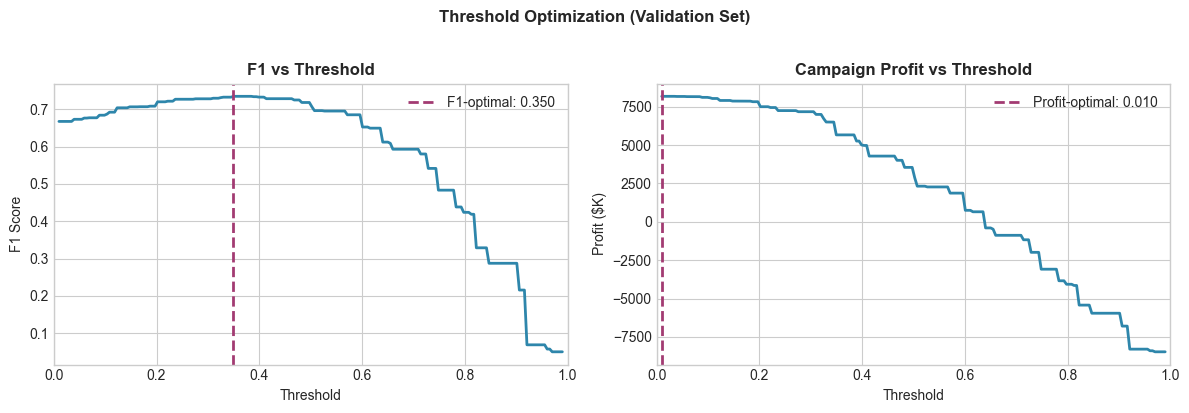


F1-optimal threshold:    0.35
Profit-optimal threshold: 0.010
Selected for deployment:  0.35 (F1-optimal, more conservative)


In [47]:
prob_val = MODEL.predict_proba(X_vl)[:, 1]

thresholds = np.linspace(0.01, 0.99, 200)

f1_scores = [f1_score(y_val, (prob_val >= t).astype(int)) for t in thresholds]
best_f1_t = thresholds[np.argmax(f1_scores)]

profits = []
for t in thresholds:
    pred = (prob_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    profit = tp * (CONFIG['avg_clv'] - CONFIG['retention_cost']) - fp * CONFIG['retention_cost'] - fn * CONFIG['avg_clv']
    profits.append(profit)

best_profit_t = thresholds[np.argmax(profits)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(thresholds, f1_scores, color=PALETTE[0], linewidth=2)
axes[0].axvline(best_f1_t, color=PALETTE[1], linestyle='--', linewidth=2, label=f'F1-optimal: {best_f1_t:.3f}')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('F1 Score')
axes[0].set_title('F1 vs Threshold', fontweight='bold')
axes[0].legend()
axes[0].set_xlim(0, 1)

axes[1].plot(thresholds, np.array(profits)/1000, color=PALETTE[0], linewidth=2)
axes[1].axvline(best_profit_t, color=PALETTE[1], linestyle='--', linewidth=2, label=f'Profit-optimal: {best_profit_t:.3f}')
axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Profit ($K)')
axes[1].set_title('Campaign Profit vs Threshold', fontweight='bold')
axes[1].legend()
axes[1].set_xlim(0, 1)

plt.suptitle('Threshold Optimization (Validation Set)', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('05_threshold_optimization.png', dpi=150, bbox_inches='tight')
plt.show()

THRESHOLD = round(best_f1_t, 3)
print(f"\nF1-optimal threshold:    {THRESHOLD}")
print(f"Profit-optimal threshold: {best_profit_t:.3f}")
print(f"Selected for deployment:  {THRESHOLD} (F1-optimal, more conservative)")

In [48]:
prob_test = MODEL.predict_proba(X_te)[:, 1]
pred_test = (prob_test >= THRESHOLD).astype(int)


print(f"\n{'='*70}")
print("FINAL EVALUATION — HOLD-OUT TEST SET")
print(f"{'='*70}")
print(f"ROC-AUC:       {roc_auc_score(y_test, prob_test):.4f}")
print(f"PR-AUC:        {average_precision_score(y_test, prob_test):.4f}")
print(f"Accuracy:      {accuracy_score(y_test, pred_test):.4f}")
print(f"Precision:     {precision_score(y_test, pred_test):.4f}")
print(f"Recall:        {recall_score(y_test, pred_test):.4f}")
print(f"F1-Score:      {f1_score(y_test, pred_test):.4f}")
print(f"Balanced Acc:  {balanced_accuracy_score(y_test, pred_test):.4f}")
print(f"MCC:           {matthews_corrcoef(y_test, pred_test):.4f}")
print(f"Brier Score:   {brier_score_loss(y_test, prob_test):.4f}")
print(f"Log Loss:      {log_loss(y_test, prob_test):.4f}")
print(f"{'='*70}")

cm = confusion_matrix(y_test, pred_test)
print(f"\nConfusion Matrix (threshold={THRESHOLD}):")
print(f"                 Predicted")
print(f"                 Retained  Churned")
print(f"Actual Retained    {cm[0,0]:6d}    {cm[0,1]:6d}")
print(f"       Churned      {cm[1,0]:6d}    {cm[1,1]:6d}")


print(f"\nClassification Report:")
print(classification_report(y_test, pred_test, target_names=['Retained', 'Churned']))


FINAL EVALUATION — HOLD-OUT TEST SET
ROC-AUC:       0.6975
PR-AUC:        0.6744
Accuracy:      0.6331
Precision:     0.5994
Recall:        0.7830
F1-Score:      0.6790
Balanced Acc:  0.6344
MCC:           0.2814
Brier Score:   0.2277
Log Loss:      0.7024

Confusion Matrix (threshold=0.35):
                 Predicted
                 Retained  Churned
Actual Retained      3676      3890
       Churned        1613      5821

Classification Report:
              precision    recall  f1-score   support

    Retained       0.70      0.49      0.57      7566
     Churned       0.60      0.78      0.68      7434

    accuracy                           0.63     15000
   macro avg       0.65      0.63      0.63     15000
weighted avg       0.65      0.63      0.63     15000



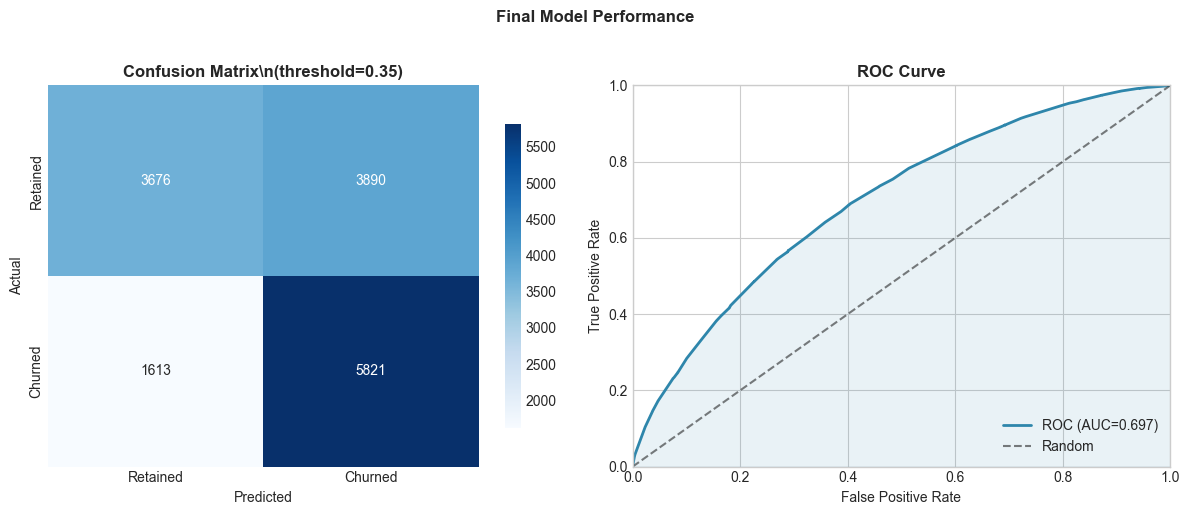

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained', 'Churned'],
            yticklabels=['Retained', 'Churned'],
            cbar_kws={'shrink': 0.8})
axes[0].set_title(f'Confusion Matrix\\n(threshold={THRESHOLD})', fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')


fpr, tpr, _ = roc_curve(y_test, prob_test)
axes[1].plot(fpr, tpr, label=f'ROC (AUC={roc_auc_score(y_test, prob_test):.3f})', 
             color=PALETTE[0], linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
axes[1].fill_between(fpr, tpr, alpha=0.1, color=PALETTE[0])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)

plt.suptitle('Final Model Performance', fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('06_final_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

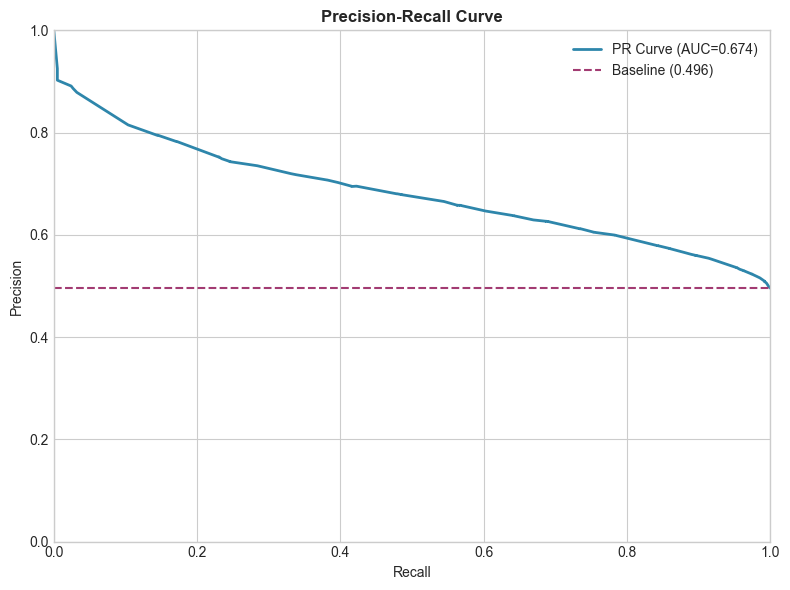

In [50]:
precision_curve, recall_curve, _ = precision_recall_curve(y_test, prob_test)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_curve, precision_curve, color=PALETTE[0], linewidth=2,
        label=f'PR Curve (AUC={average_precision_score(y_test, prob_test):.3f})')
ax.axhline(y_test.mean(), color=PALETTE[1], linestyle='--', 
           label=f'Baseline ({y_test.mean():.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold')
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('07_precision_recall.png', dpi=150, bbox_inches='tight')
plt.show()


ERROR ANALYSIS
Correct             :  9497 ( 63.3%)
False Positive      :  3890 ( 25.9%)
False Negative      :  1613 ( 10.8%)


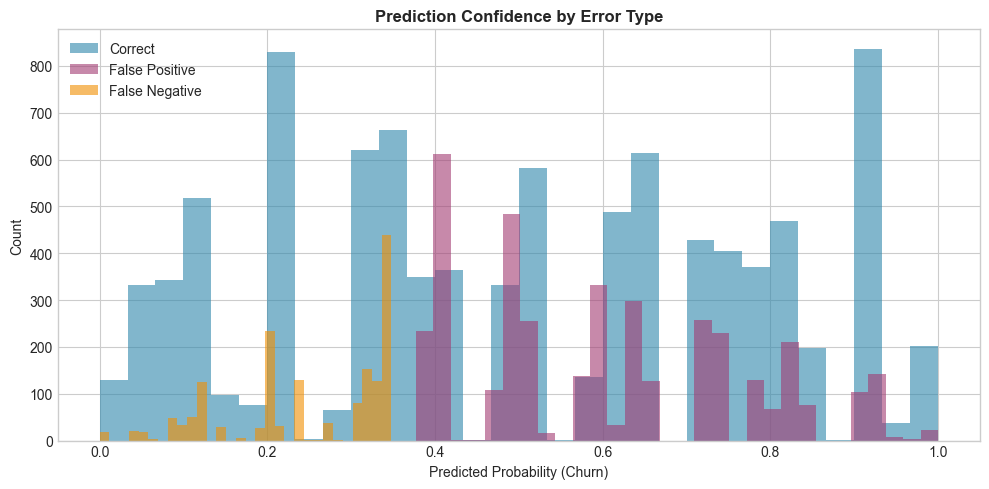

In [51]:
results_df = pd.DataFrame({
    'actual': y_test.values,
    'predicted': pred_test,
    'probability': prob_test
})

results_df['error_type'] = 'Correct'
results_df.loc[(results_df['actual'] == 0) & (results_df['predicted'] == 1), 'error_type'] = 'False Positive'
results_df.loc[(results_df['actual'] == 1) & (results_df['predicted'] == 0), 'error_type'] = 'False Negative'

error_summary = results_df['error_type'].value_counts()
print(f"\n{'='*60}")
print("ERROR ANALYSIS")
print(f"{'='*60}")
for err_type, count in error_summary.items():
    pct = count / len(results_df) * 100
    print(f"{err_type:20s}: {count:5d} ({pct:5.1f}%)")


fig, ax = plt.subplots(figsize=(10, 5))
for err_type in ['Correct', 'False Positive', 'False Negative']:
    subset = results_df[results_df['error_type'] == err_type]['probability']
    subset.hist(bins=30, alpha=0.6, label=err_type, ax=ax)
ax.set_xlabel('Predicted Probability (Churn)')
ax.set_ylabel('Count')
ax.set_title('Prediction Confidence by Error Type', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('08_error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [52]:
uncertain = results_df[
    (results_df['probability'] > THRESHOLD - 0.1) & 
    (results_df['probability'] < THRESHOLD + 0.1)
]
print(f"\nUncertain predictions (±0.1 from threshold): {len(uncertain)} ({len(uncertain)/len(results_df)*100:.1f}%)")


Uncertain predictions (±0.1 from threshold): 3756 (25.0%)


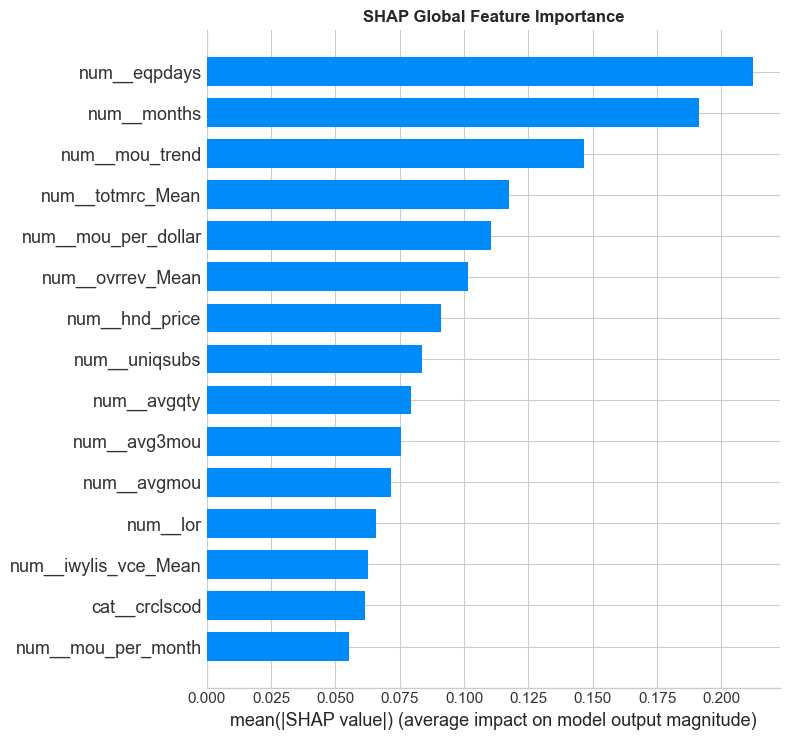

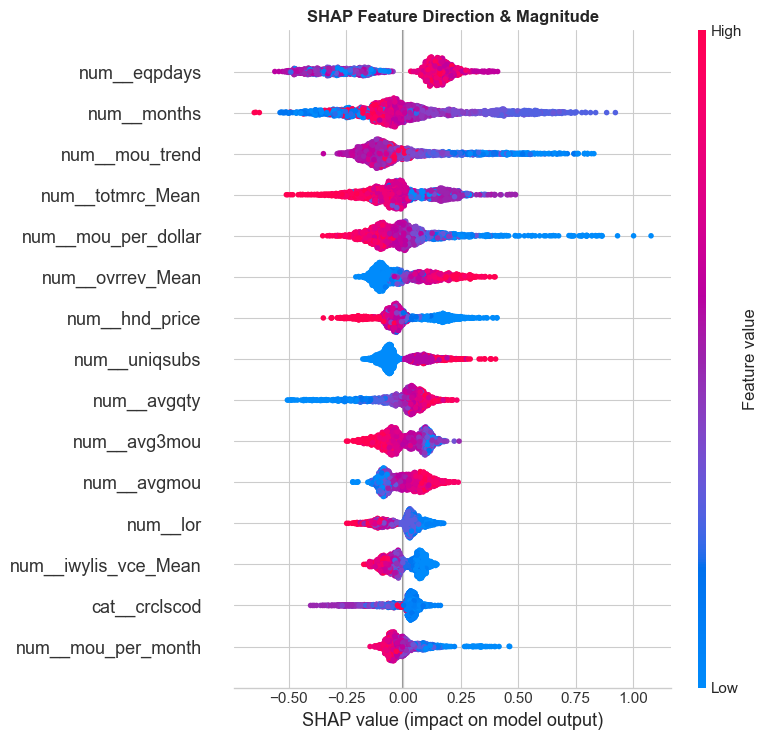

In [53]:
if hasattr(MODEL, 'calibrated_classifiers_'):
    base_model = MODEL.calibrated_classifiers_[0].estimator
else:
    base_model = MODEL

explainer = shap.TreeExplainer(base_model)
shap_sample = X_tr.sample(n=min(2000, len(X_tr)), random_state=RANDOM_STATE)
shap_values = explainer.shap_values(shap_sample)


sv = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 8))
shap.summary_plot(sv, shap_sample, plot_type='bar', max_display=15, show=False)
plt.title('SHAP Global Feature Importance', fontweight='bold')
plt.tight_layout()
plt.savefig('09_shap_global.png', dpi=150, bbox_inches='tight')
plt.show()
plt.figure(figsize=(10, 8))
shap.summary_plot(sv, shap_sample, max_display=15, show=False)
plt.title('SHAP Feature Direction & Magnitude', fontweight='bold')
plt.tight_layout()
plt.savefig('10_shap_direction.png', dpi=150, bbox_inches='tight')
plt.show()